In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ativar o tema moderno padrão do Seaborn (fundo limpo, grelhas suaves e boa tipografia)
sns.set_theme(style="whitegrid")

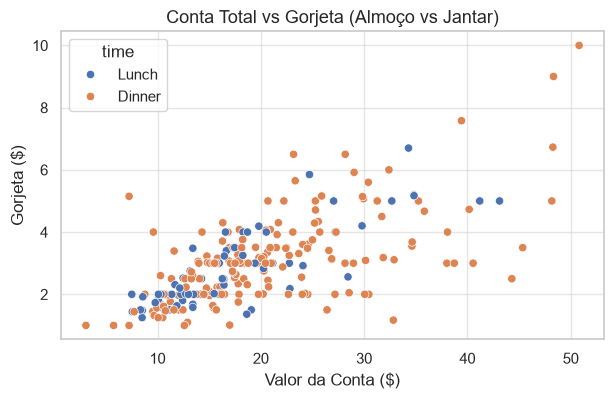

In [3]:
# Carregar um dataset clássico embutido no Seaborn
df_gorjetas = sns.load_dataset('tips')

fig, ax = plt.subplots(figsize=(7, 4))

# Seaborn desenha DIRETAMENTE no objeto 'ax' do Matplotlib!
sns.scatterplot(data=df_gorjetas, x='total_bill', y='tip', hue='time', ax=ax)

# Podes continuar a usar todos os métodos do Matplotlib:
ax.set_title("Conta Total vs Gorjeta (Almoço vs Jantar)", fontsize=13)
ax.set_xlabel("Valor da Conta ($)")
ax.set_ylabel("Gorjeta ($)")

plt.show()

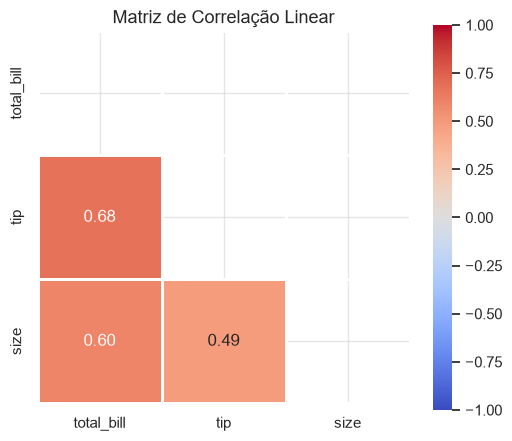

In [4]:
# 1. Calcular a matriz de correlação do Pandas
corr = df_gorjetas.corr(numeric_only=True)

# 💡 Truque de Mestre: Criar uma máscara triangular para esconder a metade repetida!
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(6, 5))

# annot=True coloca os números dentro das células; fmt='.2f' limita a 2 casas decimais
# cmap='coolwarm' (ou 'vlag') coloca azul no negativo e vermelho no positivo
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=1, ax=ax)

ax.set_title("Matriz de Correlação Linear", fontsize=13)
plt.show()

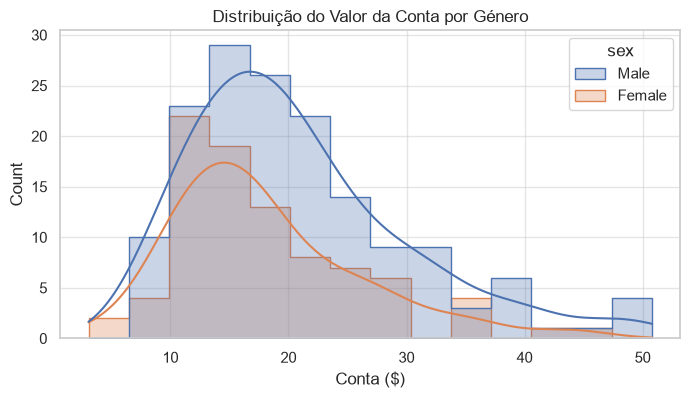

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))

# kde=True adiciona a curva suave de densidade estimada (Kernel Density Estimation)
# hue='sex' separa a distribuição entre homens e mulheres automaticamente
sns.histplot(data=df_gorjetas, x='total_bill', kde=True, hue='sex',
             element='step', alpha=0.3, ax=ax)

ax.set_title("Distribuição do Valor da Conta por Género")
ax.set_xlabel("Conta ($)")
plt.show()

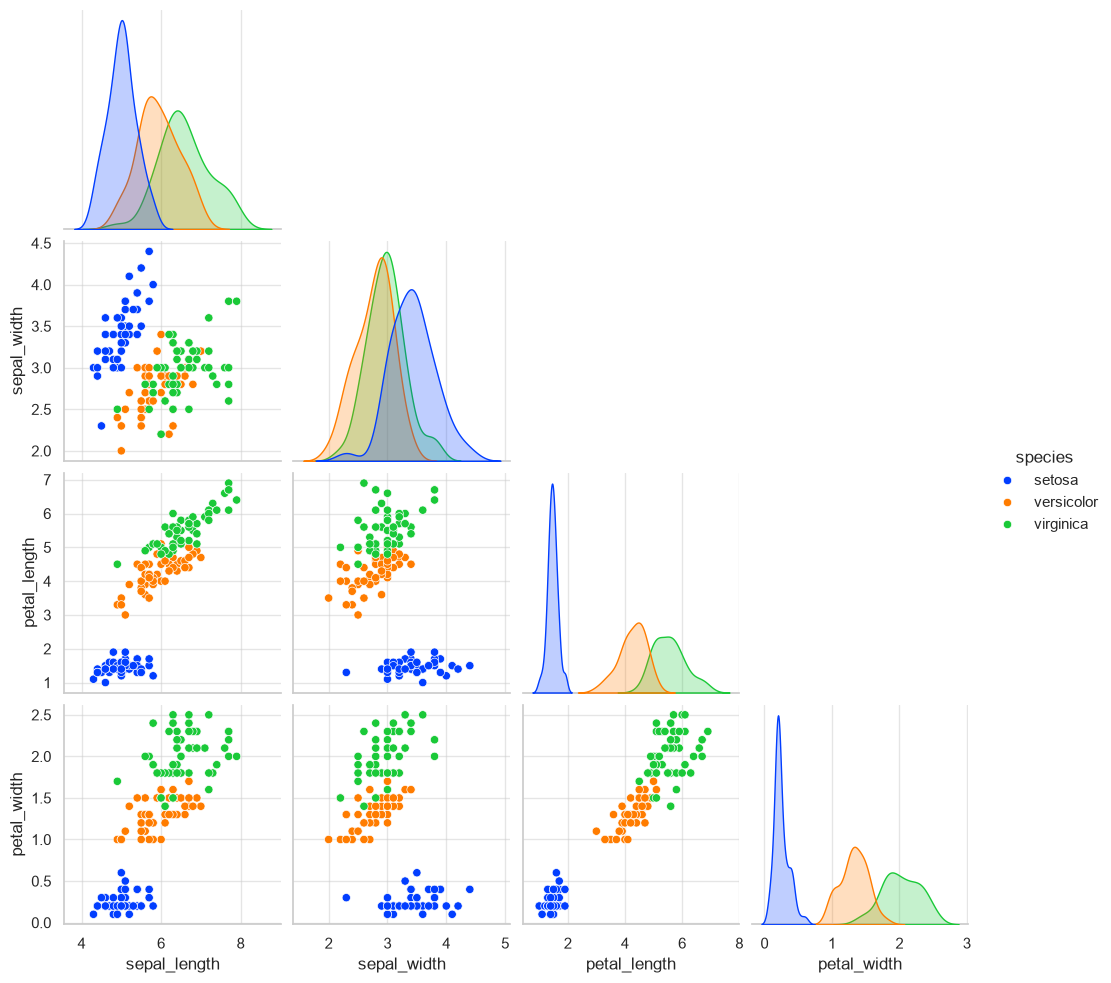

In [6]:
df_iris = sns.load_dataset('iris')

# corner=True corta a metade superior redundante (economiza tempo e espaço!)
# hue='species' colore os pontos pela classe alvo
grafico = sns.pairplot(df_iris, hue='species', corner=True, palette='bright')
plt.show()

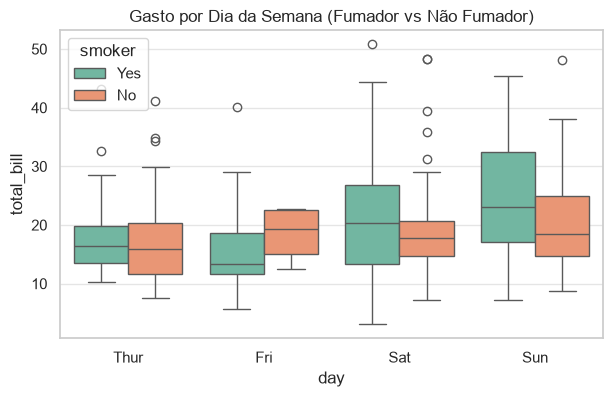

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_gorjetas, x='day', y='total_bill', hue='smoker', palette='Set2', ax=ax)
ax.set_title("Gasto por Dia da Semana (Fumador vs Não Fumador)")
plt.show()

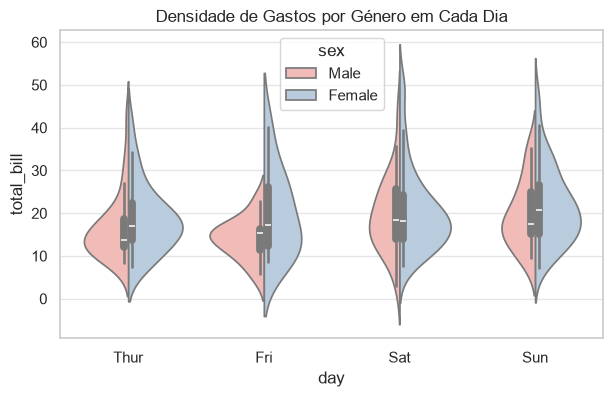

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
# split=True divide o violino ao meio, comparando duas categorias lado a lado!
sns.violinplot(data=df_gorjetas, x='day', y='total_bill', hue='sex', split=True, palette='Pastel1', ax=ax)
ax.set_title("Densidade de Gastos por Género em Cada Dia")
plt.show()

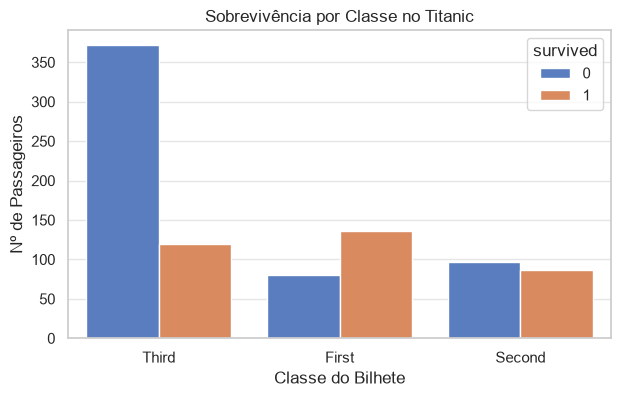

In [9]:
df_titanic = sns.load_dataset('titanic')

fig, ax = plt.subplots(figsize=(7, 4))

# Conta a frequência de cada categoria
# order garante que as barras ficam ordenadas da mais frequente para a menor
sns.countplot(
    data=df_titanic,
    x='class',
    hue='survived',
    order=['Third', 'First', 'Second'],
    palette='muted',
    ax=ax
)

ax.set_title("Sobrevivência por Classe no Titanic")
ax.set_xlabel("Classe do Bilhete")
ax.set_ylabel("Nº de Passageiros")
plt.show()

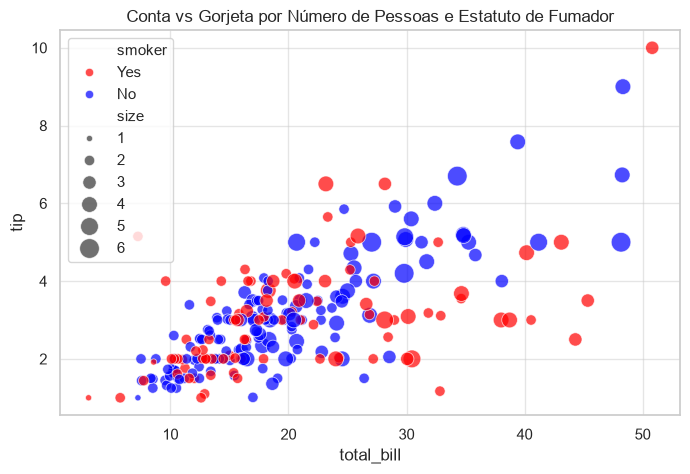

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=df_gorjetas,
    x='total_bill',
    y='tip',
    hue='smoker',          # Cor: Fumador ou Não
    size='size',            # Tamanho da bolha: Número de pessoas na mesa
    sizes=(20, 200),        # Intervalo de tamanhos dos marcadores
    alpha=0.7,
    palette=['red', 'blue'],
    ax=ax
)

ax.set_title("Conta vs Gorjeta por Número de Pessoas e Estatuto de Fumador")
plt.show()

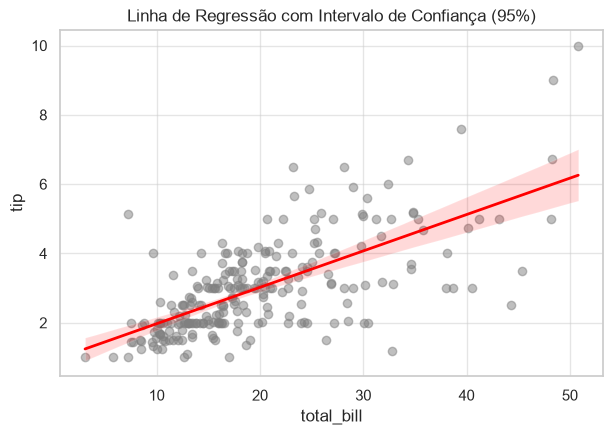

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))

# ci=95 ativa a faixa de confiança sombreada
# scatter_kws e line_kws permitem personalizar pontos e linha de forma independente
sns.regplot(
    data=df_gorjetas,
    x='total_bill',
    y='tip',
    ci=95,
    scatter_kws={'alpha': 0.5, 'color': 'gray'},
    line_kws={'color': 'red', 'linewidth': 2},
    ax=ax
)

ax.set_title("Linha de Regressão com Intervalo de Confiança (95%)")
plt.show()

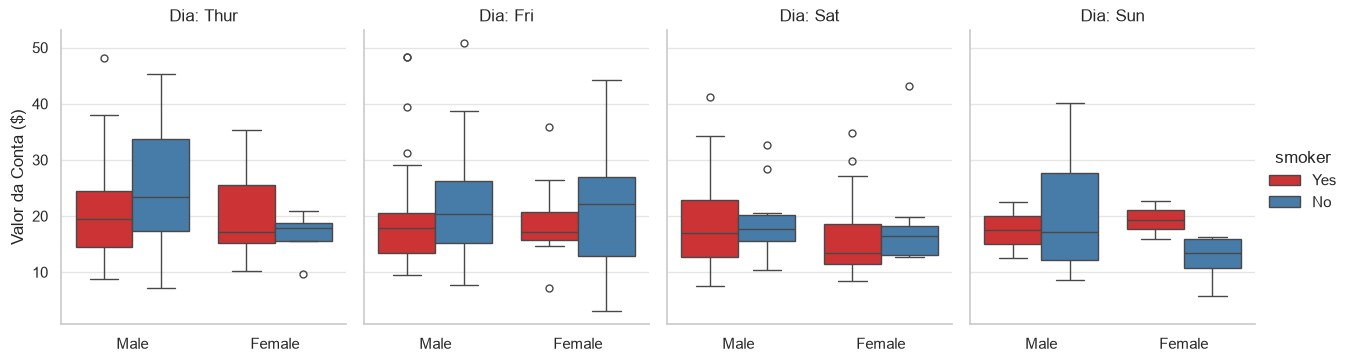

In [12]:
# col='day' cria uma coluna de gráfico para cada dia diferente!
# kind pode ser: 'box', 'violin', 'bar', 'count', etc.
g = sns.catplot(
    data=df_gorjetas,
    x='sex',
    y='total_bill',
    hue='smoker',
    col='day',
    kind='box',
    height=4,
    aspect=0.8,
    palette='Set1'
)

g.set_axis_labels("", "Valor da Conta ($)")
g.set_titles("Dia: {col_name}")
plt.show()

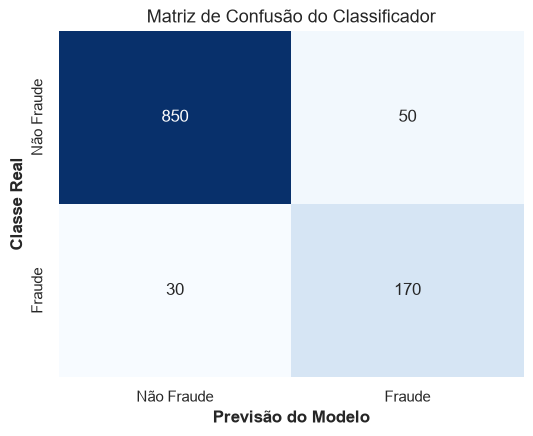

In [13]:
matriz_confusao = np.array([
    [850, 50],   # Classe 0: Real Negativo (850 acertados, 50 falsos positivos)
    [30,  170]   # Classe 1: Real Positivo (30 falsos negativos, 170 acertados)
])

classes = ['Não Fraude', 'Fraude']

fig, ax = plt.subplots(figsize=(6, 4.5))

sns.heatmap(
    matriz_confusao,
    annot=True,
    fmt='d',           # 'd' formata como inteiro em vez de notação científica
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes,
    cbar=False,
    ax=ax
)

ax.set_xlabel('Previsão do Modelo', fontweight='bold')
ax.set_ylabel('Classe Real', fontweight='bold')
ax.set_title('Matriz de Confusão do Classificador', fontsize=13)

plt.show()

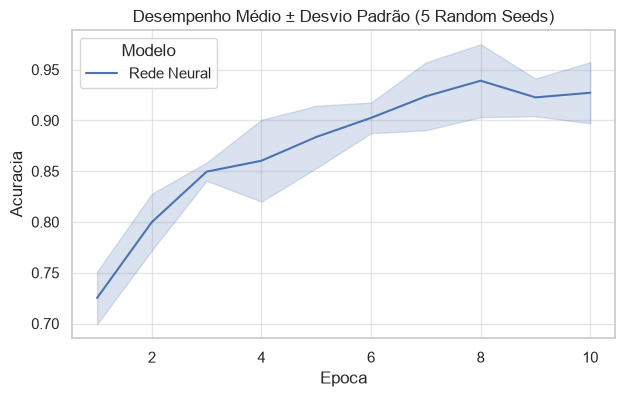

In [14]:
# Simulando 5 execuções (seeds) de treino ao longo de 10 épocas
np.random.seed(42)
dados_treino = []
for seed in range(5):
    for epoca in range(1, 11):
        acuracia = 0.6 + 0.35 * (1 - np.exp(-0.4 * epoca)) + np.random.normal(0, 0.03)
        dados_treino.append({'Epoca': epoca, 'Acuracia': acuracia, 'Modelo': 'Rede Neural'})

df_exp = pd.DataFrame(dados_treino)

fig, ax = plt.subplots(figsize=(7, 4))

# errorbar='ci' (intervalo de confiança 95%) ou errorbar='sd' (desvio padrão)
sns.lineplot(data=df_exp, x='Epoca', y='Acuracia', hue='Modelo', errorbar='sd', ax=ax)

ax.set_title("Desempenho Médio ± Desvio Padrão (5 Random Seeds)")
plt.show()

C:\Users\filbr\AppData\Local\Temp\ipykernel_23324\728436001.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


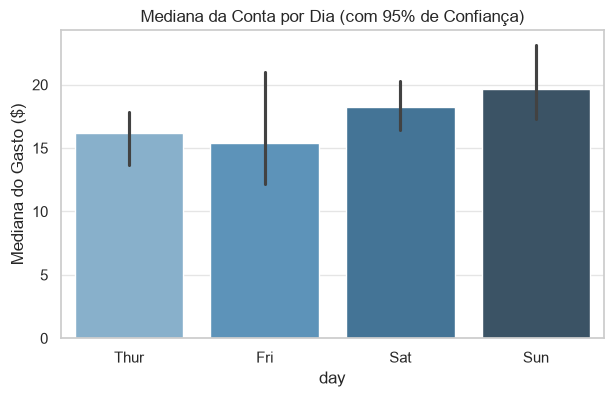

In [15]:
df_tips = sns.load_dataset('tips')

fig, ax = plt.subplots(figsize=(7, 4))

# Compara a MEDIANA da conta por dia (evita distorção de contas gigantes)
sns.barplot(
    data=df_tips,
    x='day',
    y='total_bill',
    estimator=np.median,
    errorbar=('ci', 95), # Intervalo de confiança da mediana
    palette='Blues_d',
    ax=ax
)

ax.set_title("Mediana da Conta por Dia (com 95% de Confiança)")
ax.set_ylabel("Mediana do Gasto ($)")
plt.show()

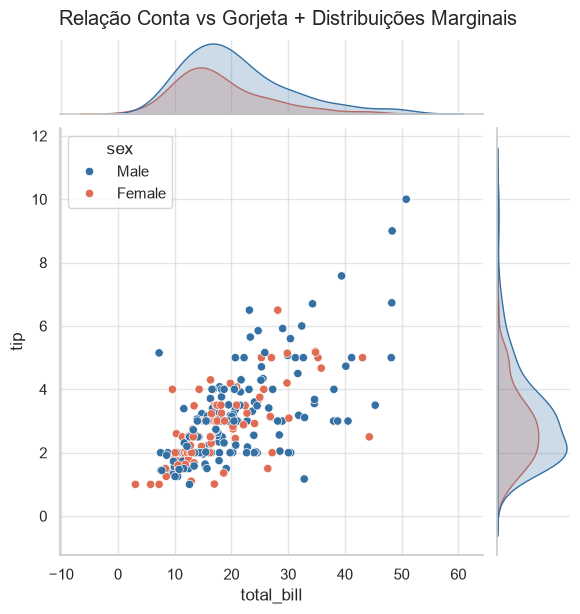

In [16]:
# kind pode ser 'scatter', 'kde', 'hist' ou 'reg' (com linha de regressão!)
g = sns.jointplot(
    data=df_tips,
    x='total_bill',
    y='tip',
    hue='sex',
    kind='scatter',
    marginal_kws=dict(fill=True), # Preenche os histogramas laterais
    palette=['#3470a3', '#e06d53'],
    height=6
)

g.figure.suptitle("Relação Conta vs Gorjeta + Distribuições Marginais", y=1.02)
plt.show()

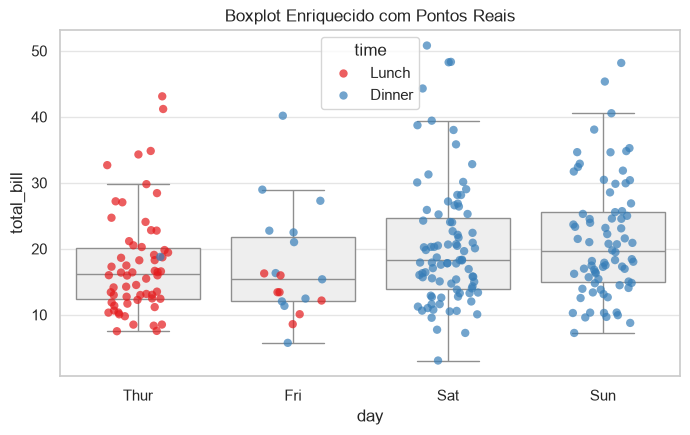

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# 1. Desenhar a estrutura estatística (caixa cinzenta suave)
sns.boxplot(data=df_tips, x='day', y='total_bill', color='#eeeeee', showfliers=False, ax=ax)

# 2. Desenhar os pontos reais por cima com jitter (tremor horizontal para não sobrepor)
sns.stripplot(data=df_tips, x='day', y='total_bill', hue='time',
              jitter=0.2, alpha=0.7, size=6, palette='Set1', ax=ax)

ax.set_title("Boxplot Enriquecido com Pontos Reais")
plt.show()

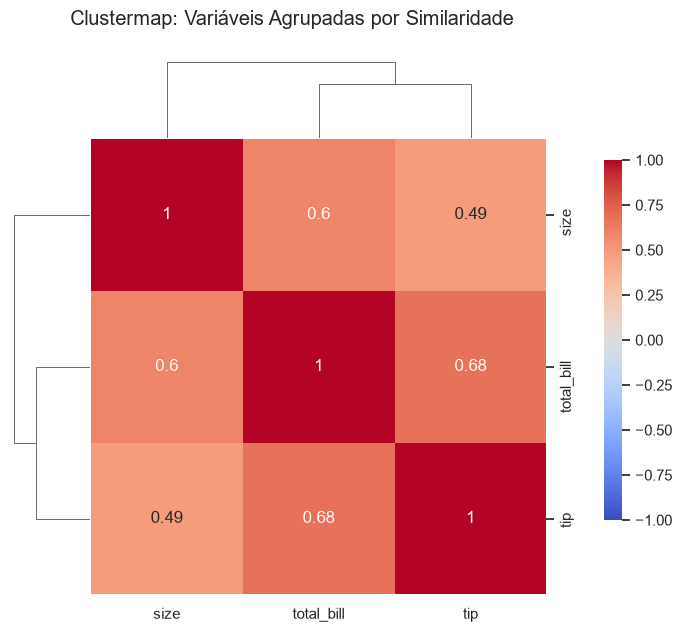

In [18]:
# Correlação entre variáveis numéricas
corr = df_tips.corr(numeric_only=True)

# O clustermap cria a sua própria figura com dendrogramas
g = sns.clustermap(
    corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    figsize=(6, 6),
    dendrogram_ratio=(0.15, 0.15), # Tamanho das árvores de decisão laterais
    cbar_pos=(1.02, 0.2, 0.03, 0.6) # Posição da barra de escala
)

g.figure.suptitle("Clustermap: Variáveis Agrupadas por Similaridade", y=1.05)
plt.show()

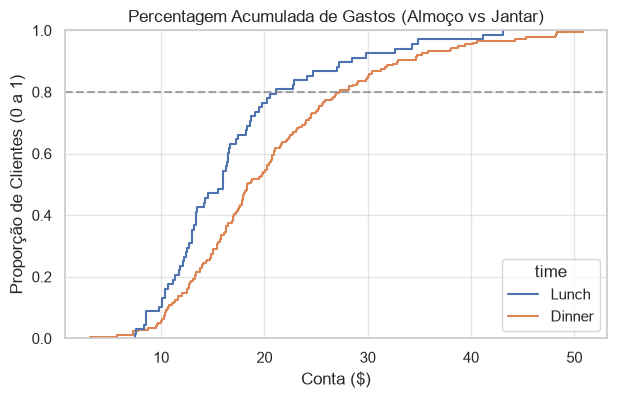

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))

# Plota a percentagem acumulada de 0 a 100% (0.0 a 1.0)
sns.ecdfplot(data=df_tips, x='total_bill', hue='time', ax=ax)

# Linha de referência nos 80% dos clientes
ax.axhline(0.80, color='gray', linestyle='--', alpha=0.7)
ax.set_title("Percentagem Acumulada de Gastos (Almoço vs Jantar)")
ax.set_xlabel("Conta ($)")
ax.set_ylabel("Proporção de Clientes (0 a 1)")

plt.show()